# Solving the n-Queens Problem using Local Search

Student Name: Trương Chí Long - 3123410198

I have used the following AI tools: Gemini 4 Argon and Copilot

I understand that my submission needs to be my own work: T.C.L


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

n = 4 | Số láng giềng = 12 | Bàn cờ ngẫu nhiên [3 3 2 1]: conflicts = 4 | Cấu hình [1, 3, 0, 2]: conflicts = 0
n = 8 | Số láng giềng = 56 | Bàn cờ ngẫu nhiên [4 4 0 1 7 1 7 1]: conflicts = 8
Board with 8 conflicts.


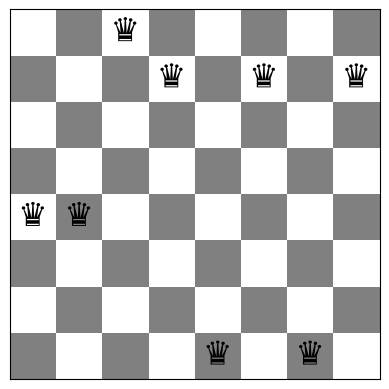

In [5]:
# Bài 2: Khảo sát kích thước lân cận và so sánh bàn cờ ngẫu nhiên trên n=4 và n=8
np.random.seed(1234)
board_4_rand = random_board(4)
board_4_opt = [1, 3, 0, 2]
board_8_rand = random_board(8)

print(f"n = 4 | Số láng giềng = {4*(4-1)} | Bàn cờ ngẫu nhiên {board_4_rand}: conflicts = {conflicts(board_4_rand)} | Cấu hình [1, 3, 0, 2]: conflicts = {conflicts(board_4_opt)}")
print(f"n = 8 | Số láng giềng = {8*(8-1)} | Bàn cờ ngẫu nhiên {board_8_rand}: conflicts = {conflicts(board_8_rand)}")
show_board(board_8_rand, fontsize=24)

Board with 4 conflicts.


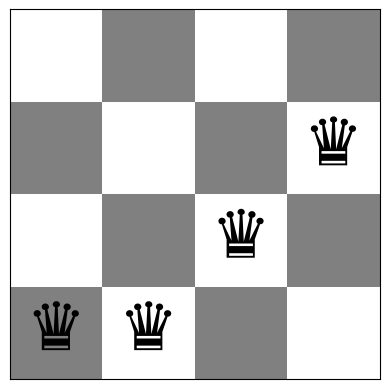

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


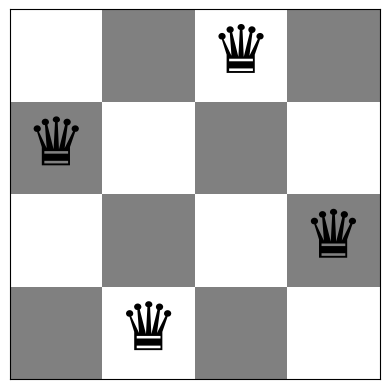

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

Step 1: conflicts = 6, board = [7 3 6 5 4 4 0 5]
Step 2: conflicts = 3, board = [7 3 6 2 4 4 0 5]
Step 3: conflicts = 2, board = [7 3 6 2 4 6 0 5]
Step 4: conflicts = 1, board = [7 3 7 2 4 6 0 5]

[Steepest-Ascent HC] Kết thúc sau 4 bước, 281 lần gọi conflicts(), f_cuối = 1, thời gian = 3.045 ms
Board with 1 conflicts.


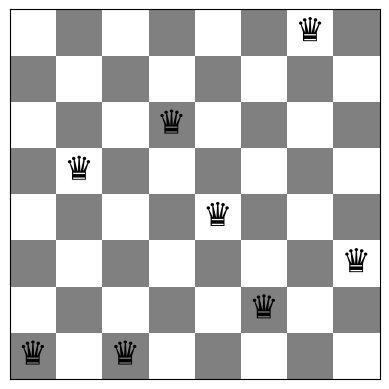

In [6]:
import time

def steepest_ascend_hc(board, return_history=False, verbose=False):
    """
    Steepest-ascend Hill Climbing:
    Đánh giá toàn bộ n*(n-1) láng giềng, chọn láng giềng giảm xung đột nhiều nhất.
    Dừng khi không có láng giềng nào tốt hơn trạng thái hiện tại.
    """
    n = len(board)
    current = np.array(board, copy=True)
    current_obj = conflicts(current)
    history = [current_obj]
    steps = 0
    evals = 1

    while True:
        best_obj = current_obj
        best_candidates = []

        for col in range(n):
            orig_row = current[col]
            for row in range(n):
                if row == orig_row:
                    continue
                neighbor = current.copy()
                neighbor[col] = row
                obj = conflicts(neighbor)
                evals += 1

                if obj < best_obj:
                    best_obj = obj
                    best_candidates = [neighbor]
                elif obj == best_obj and len(best_candidates) > 0:
                    best_candidates.append(neighbor)

        if best_obj < current_obj:
            # Phá hòa ngẫu nhiên nếu có nhiều láng giềng cùng đạt mức cải thiện tốt nhất
            current = best_candidates[np.random.randint(len(best_candidates))]
            current_obj = best_obj
            steps += 1
            history.append(current_obj)
            if verbose:
                print(f"Step {steps}: conflicts = {current_obj}, board = {current}")
            if current_obj == 0:
                break
        else:
            break

    if return_history:
        return current, current_obj, steps, evals, history
    return current

# Chạy thử nghiệm Task 1 trên n=8
np.random.seed(1234)
init_b8 = random_board(8)
t0 = time.perf_counter()
sol_sa, obj_sa, steps_sa, evals_sa, hist_sa = steepest_ascend_hc(init_b8, return_history=True, verbose=True)
dt = (time.perf_counter() - t0) * 1000
print(f"\n[Steepest-Ascent HC] Kết thúc sau {steps_sa} bước, {evals_sa} lần gọi conflicts(), f_cuối = {obj_sa}, thời gian = {dt:.3f} ms")
show_board(sol_sa, fontsize=24)

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [7]:
def inefficient_stochastic_hc(board, return_history=False, verbose=False):
    """
    Inefficient Stochastic Hill Climbing:
    Đánh giá toàn bộ n*(n-1) láng giềng, thu thập tất cả các bước đi tốt hơn (uphill moves)
    và chọn ngẫu nhiên 1 bước trong số đó.
    """
    n = len(board)
    current = np.array(board, copy=True)
    current_obj = conflicts(current)
    history = [current_obj]
    steps = 0
    evals = 1

    while True:
        uphill_moves = []

        for col in range(n):
            orig_row = current[col]
            for row in range(n):
                if row == orig_row:
                    continue
                neighbor = current.copy()
                neighbor[col] = row
                obj = conflicts(neighbor)
                evals += 1

                if obj < current_obj:
                    uphill_moves.append((neighbor, obj))

        if len(uphill_moves) > 0:
            idx = np.random.randint(len(uphill_moves))
            current, current_obj = uphill_moves[idx]
            steps += 1
            history.append(current_obj)
            if verbose:
                print(f"Step {steps}: conflicts = {current_obj}, board = {current} (chọn từ {len(uphill_moves)} bước cải thiện)")
            if current_obj == 0:
                break
        else:
            break

    if return_history:
        return current, current_obj, steps, evals, history
    return current

# Chạy thử nghiệm Task 2 trên n=8
np.random.seed(1234)
t0 = time.perf_counter()
sol_ishc, obj_ishc, steps_ishc, evals_ishc, hist_ishc = inefficient_stochastic_hc(init_b8, return_history=True, verbose=True)
dt = (time.perf_counter() - t0) * 1000
print(f"\n[Inefficient Stochastic HC] Kết thúc sau {steps_ishc} bước, {evals_ishc} lần gọi conflicts(), f_cuối = {obj_ishc}, thời gian = {dt:.3f} ms")

Step 1: conflicts = 6, board = [7 3 6 5 1 4 0 1] (chọn từ 28 bước cải thiện)
Step 2: conflicts = 5, board = [7 3 6 0 1 4 0 1] (chọn từ 16 bước cải thiện)
Step 3: conflicts = 4, board = [7 3 6 0 1 4 7 1] (chọn từ 12 bước cải thiện)
Step 4: conflicts = 3, board = [7 3 6 0 1 4 7 2] (chọn từ 4 bước cải thiện)
Step 5: conflicts = 2, board = [7 3 6 0 1 5 7 2] (chọn từ 2 bước cải thiện)

[Inefficient Stochastic HC] Kết thúc sau 5 bước, 337 lần gọi conflicts(), f_cuối = 2, thời gian = 4.369 ms


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [8]:
def efficient_stochastic_hc(board, max_bad_tries=None, return_history=False, verbose=False):
    """
    Efficient Stochastic (First-Choice) Hill Climbing:
    Sinh ngẫu nhiên từng láng giềng một và nhận ngay nếu tốt hơn.
    Lý giải chọn ngưỡng dừng x (max_bad_tries):
    Với N = n*(n-1) láng giềng, theo bài toán Coupon Collector, xác suất chưa lấy mẫu được
    1 láng giềng cải thiện duy nhất sau x lần thử có hoàn lại là (1 - 1/N)^x ≈ exp(-x/N).
    Nếu chọn x = 3 * N = 3 * n * (n - 1), xác suất bỏ sót nước đi cải thiện chỉ còn exp(-3) ≈ 4.98%.
    """
    n = len(board)
    if max_bad_tries is None:
        max_bad_tries = 3 * n * (n - 1)

    current = np.array(board, copy=True)
    current_obj = conflicts(current)
    history = [current_obj]
    steps = 0
    evals = 1
    bad_tries = 0

    while current_obj > 0 and bad_tries < max_bad_tries:
        col = np.random.randint(0, n)
        row = np.random.randint(0, n - 1)
        if row >= current[col]:
            row += 1

        neighbor = current.copy()
        neighbor[col] = row
        obj = conflicts(neighbor)
        evals += 1

        if obj < current_obj:
            current = neighbor
            current_obj = obj
            bad_tries = 0
            steps += 1
            history.append(current_obj)
            if verbose:
                print(f"Step {steps}: conflicts = {current_obj}, board = {current}")
        else:
            bad_tries += 1

    if return_history:
        return current, current_obj, steps, evals, history
    return current

# Chạy thử nghiệm Task 3 trên n=8
np.random.seed(1234)
t0 = time.perf_counter()
sol_eshc, obj_eshc, steps_eshc, evals_eshc, hist_eshc = efficient_stochastic_hc(init_b8, return_history=True, verbose=True)
dt = (time.perf_counter() - t0) * 1000
print(f"\n[Efficient Stochastic HC] Kết thúc sau {steps_eshc} bước cải thiện, {evals_eshc} lần gọi conflicts(), f_cuối = {obj_eshc}, thời gian = {dt:.3f} ms")

Step 1: conflicts = 7, board = [7 3 6 5 4 4 0 4]
Step 2: conflicts = 5, board = [7 3 6 5 5 4 0 4]
Step 3: conflicts = 4, board = [7 3 6 7 5 4 0 4]
Step 4: conflicts = 3, board = [7 3 6 7 5 0 0 4]
Step 5: conflicts = 2, board = [7 3 6 2 5 0 0 4]
Step 6: conflicts = 1, board = [7 3 6 2 5 5 0 4]

[Efficient Stochastic HC] Kết thúc sau 6 bước cải thiện, 235 lần gọi conflicts(), f_cuối = 1, thời gian = 4.030 ms


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [9]:
def random_restart_hc(n, hc_func, max_restarts=100, seed=None):
    """
    Khởi tạo lại bàn cờ ngẫu nhiên tối đa max_restarts lần cho thuật toán hc_func.
    Dừng ngay khi tìm được nghiệm hợp lệ (conflicts == 0).
    """
    if seed is not None:
        np.random.seed(seed)

    best_board = None
    best_obj = float('inf')
    total_steps = 0
    total_evals = 0

    for restart in range(1, max_restarts + 1):
        b = random_board(n)
        sol, obj, steps, evals, _ = hc_func(b, return_history=True)
        total_steps += steps
        total_evals += evals

        if obj < best_obj:
            best_obj = obj
            best_board = sol.copy()

        if best_obj == 0:
            return best_board, best_obj, restart, total_steps, total_evals

    return best_board, best_obj, max_restarts, total_steps, total_evals

# Thử nghiệm Random Restart tối đa 100 lần cho 3 biến thể trên n=4 và n=8
variants = [
    ("Steepest-Ascent HC", steepest_ascend_hc),
    ("Inefficient Stochastic HC", inefficient_stochastic_hc),
    ("Efficient Stochastic HC", efficient_stochastic_hc)
]

for n_size in [4, 8]:
    print(f"=== Random Restart trên bàn cờ n = {n_size} (Max 100 restarts) ===")
    for name, func in variants:
        t0 = time.perf_counter()
        sol, best_f, restarts, tot_steps, tot_evals = random_restart_hc(n_size, func, max_restarts=100, seed=1234)
        dt = (time.perf_counter() - t0) * 1000
        print(f"{name:27s} | f_best = {best_f} | Số lần khởi động = {restarts:2d} | Tổng bước = {tot_steps:3d} | Tổng evals = {tot_evals:5d} | Thời gian = {dt:.2f} ms")

=== Random Restart trên bàn cờ n = 4 (Max 100 restarts) ===
Steepest-Ascent HC          | f_best = 0 | Số lần khởi động =  2 | Tổng bước =   3 | Tổng evals =    50 | Thời gian = 0.85 ms
Inefficient Stochastic HC   | f_best = 0 | Số lần khởi động =  4 | Tổng bước =   7 | Tổng evals =   124 | Thời gian = 0.63 ms
Efficient Stochastic HC     | f_best = 0 | Số lần khởi động =  1 | Tổng bước =   3 | Tổng evals =    26 | Thời gian = 0.21 ms
=== Random Restart trên bàn cờ n = 8 (Max 100 restarts) ===
Steepest-Ascent HC          | f_best = 0 | Số lần khởi động =  5 | Tổng bước =  19 | Tổng evals =  1293 | Thời gian = 10.14 ms
Inefficient Stochastic HC   | f_best = 0 | Số lần khởi động =  1 | Tổng bước =   6 | Tổng evals =   337 | Thời gian = 2.55 ms
Efficient Stochastic HC     | f_best = 0 | Số lần khởi động = 19 | Tổng bước =  89 | Tổng evals =  4752 | Thời gian = 55.69 ms


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

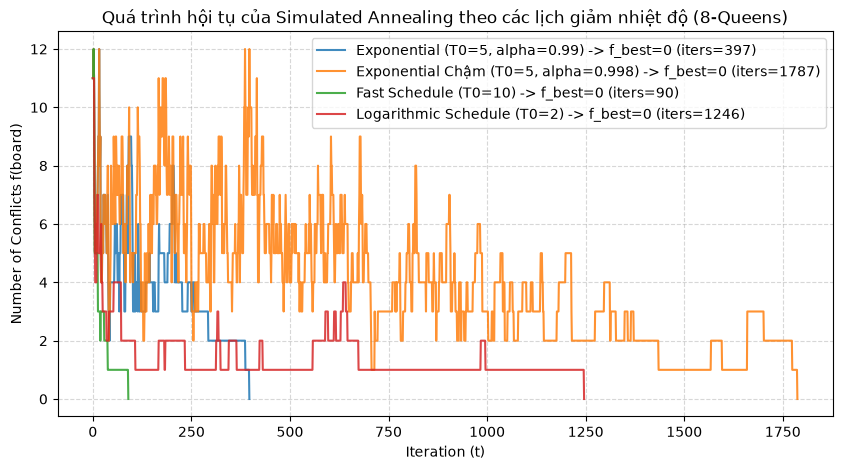

In [10]:
def simulated_annealing(board, T0=10.0, alpha=0.995, max_iter=5000, schedule="exponential", eta=0.002, return_history=False):
    """
    Simulated Annealing cho bài toán n-Queens.
    Hỗ trợ các lịch giảm nhiệt: 'exponential', 'linear', 'fast', 'logarithmic'.
    Với delta = f(new) - f(current):
      - Nếu delta < 0 (hoặc <= 0): luôn chấp nhận.
      - Nếu delta > 0: chấp nhận với xác suất exp(-delta / T).
    """
    n = len(board)
    current = np.array(board, copy=True)
    current_obj = conflicts(current)
    best_board = current.copy()
    best_obj = current_obj
    history = [current_obj]
    evals = 1

    for t in range(1, max_iter + 1):
        if current_obj == 0:
            break

        if schedule == "exponential":
            T = T0 * (alpha ** t)
        elif schedule == "linear":
            T = max(0.0, T0 - eta * t)
        elif schedule == "fast":
            T = T0 / (1.0 + t)
        elif schedule == "logarithmic":
            T = T0 / np.log1p(t)
        else:
            T = T0 * (alpha ** t)

        if T <= 1e-8:
            break

        col = np.random.randint(0, n)
        row = np.random.randint(0, n - 1)
        if row >= current[col]:
            row += 1

        neighbor = current.copy()
        neighbor[col] = row
        neighbor_obj = conflicts(neighbor)
        evals += 1

        delta = neighbor_obj - current_obj
        if delta <= 0 or np.random.rand() < np.exp(-delta / T):
            current = neighbor
            current_obj = neighbor_obj
            if current_obj < best_obj:
                best_obj = current_obj
                best_board = current.copy()

        history.append(current_obj)

    if return_history:
        return best_board, best_obj, len(history) - 1, evals, history
    return best_board

# Trực quan hóa quá trình tìm kiếm của Simulated Annealing với các lịch nhiệt khác nhau trên n=8
np.random.seed(42)
test_b8 = random_board(8)

schedules_cfg = [
    ("Exponential (T0=5, alpha=0.99)", 5.0, 0.99, "exponential"),
    ("Exponential Chậm (T0=5, alpha=0.998)", 5.0, 0.998, "exponential"),
    ("Fast Schedule (T0=10)", 10.0, 0.99, "fast"),
    ("Logarithmic Schedule (T0=2)", 2.0, 0.99, "logarithmic")
]

plt.figure(figsize=(10, 5))
for label, t_init, a_val, sched_type in schedules_cfg:
    np.random.seed(42)
    sol, b_obj, iters, evs, hist = simulated_annealing(
        test_b8, T0=t_init, alpha=a_val, max_iter=2000, schedule=sched_type, return_history=True
    )
    plt.plot(hist, label=f"{label} -> f_best={b_obj} (iters={iters})", alpha=0.85)

plt.xlabel("Iteration (t)")
plt.ylabel("Number of Conflicts f(board)")
plt.title("Quá trình hội tụ của Simulated Annealing theo các lịch giảm nhiệt độ (8-Queens)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [23]:
# Ensure pandas is installed in this notebook environment
import sys
!{sys.executable} -m pip install pandas

import pandas as pd
import sys

def benchmark_algorithms(sizes=[4, 8], n_runs=100, seed=1234):
    records = []
    algos = [
        ("Steepest asc. HC", lambda b: steepest_ascend_hc(b, return_history=True)),
        ("Ineff. Stochastic HC", lambda b: inefficient_stochastic_hc(b, return_history=True)),
        ("Efficient Stochastic HC", lambda b: efficient_stochastic_hc(b, return_history=True)),
        ("Simulated Annealing", lambda b: simulated_annealing(b, T0=4.0, alpha=0.995, max_iter=4000, return_history=True))
    ]

    for n in sizes:
        np.random.seed(seed)
        starting_boards = [random_board(n) for _ in range(n_runs)]

        for algo_name, algo_fn in algos:
            np.random.seed(seed + 99)
            runtimes = []
            final_conflicts = []
            steps_list = []
            evals_list = []

            for b in starting_boards:
                t0 = time.perf_counter()
                _, obj, steps, evals, _ = algo_fn(b)
                dt_ms = (time.perf_counter() - t0) * 1000.0
                runtimes.append(dt_ms)
                final_conflicts.append(obj)
                steps_list.append(steps)
                evals_list.append(evals)

            success_rate = np.mean(np.array(final_conflicts) == 0) * 100.0
            records.append({
                "Algorithm": algo_name,
                "Board size": n,
                "Avg. Run time (ms)": round(np.mean(runtimes), 3),
                "Avg. number of conflicts": round(np.mean(final_conflicts), 2),
                "% of runs ending in optimal solution": f"{success_rate:.1f}%",
                "Avg. Steps": round(np.mean(steps_list), 1),
                "Avg. Evals": round(np.mean(evals_list), 1)
            })

    return pd.DataFrame(records)

df_comparison = benchmark_algorithms(sizes=[4, 8], n_runs=100)
# Ensure tabulate is installed for DataFrame.to_markdown()
try:
    import tabulate  # noqa: F401
except ImportError:
    !{sys.executable} -m pip install tabulate

print(df_comparison.to_markdown(index=False))

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
| Algorithm               |   Board size |   Avg. Run time (ms) |   Avg. number of conflicts | % of runs ending in optimal solution   |   Avg. Steps |   Avg. Evals |
|:------------------------|-------------:|---------------------:|---------------------------:|:---------------------------------------|-------------:|-------------:|
| Steepest asc. HC        |            4 |                0.13  |                       0.56 | 46.0%                                  |          1.6 |         26.2 |
| Ineff. Stochastic HC    |            4 |                0.16  |                       0.76 | 36.0%                                  |          2   |         32.3 |
| Efficient Stochastic HC |            4 |                0.315 |                       0.9  | 29.0%                                  |          1.9 |         36.8 |
| Simulated An

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

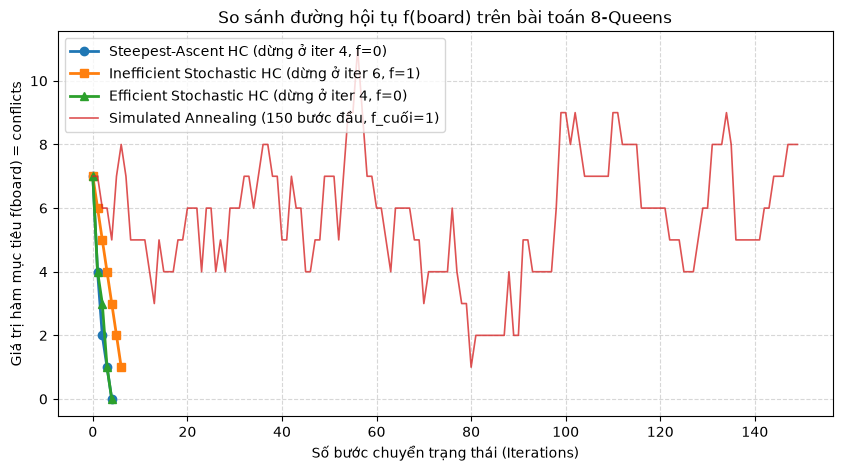

In [13]:
np.random.seed(7)
sample_board_8 = random_board(8)

_, _, _, _, h_steep = steepest_ascend_hc(sample_board_8, return_history=True)
_, _, _, _, h_ineff = inefficient_stochastic_hc(sample_board_8, return_history=True)
_, _, _, _, h_eff = efficient_stochastic_hc(sample_board_8, return_history=True)
_, _, _, _, h_sa = simulated_annealing(sample_board_8, T0=4.0, alpha=0.99, max_iter=600, return_history=True)

plt.figure(figsize=(10, 5))
plt.plot(h_steep, marker='o', linewidth=2, label=f"Steepest-Ascent HC (dừng ở iter {len(h_steep)-1}, f={h_steep[-1]})")
plt.plot(h_ineff, marker='s', linewidth=2, label=f"Inefficient Stochastic HC (dừng ở iter {len(h_ineff)-1}, f={h_ineff[-1]})")
plt.plot(h_eff, marker='^', linewidth=2, label=f"Efficient Stochastic HC (dừng ở iter {len(h_eff)-1}, f={h_eff[-1]})")
plt.plot(h_sa[:150], linewidth=1.2, alpha=0.8, label=f"Simulated Annealing (150 bước đầu, f_cuối={min(h_sa)})")

plt.xlabel("Số bước chuyển trạng thái (Iterations)")
plt.ylabel("Giá trị hàm mục tiêu f(board) = conflicts")
plt.title("So sánh đường hội tụ f(board) trên bài toán 8-Queens")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

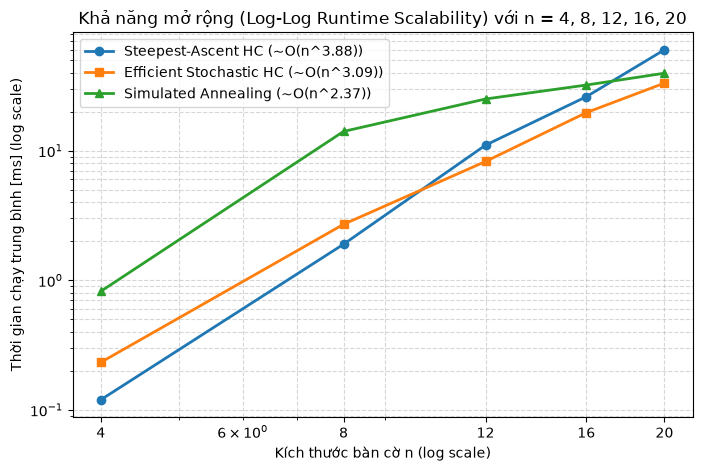

In [14]:
sizes_scale = [4, 8, 12, 16, 20]
n_trials_scale = 20

times_steep = []
times_eff = []
times_sa = []

for n in sizes_scale:
    np.random.seed(1234)
    boards_n = [random_board(n) for _ in range(n_trials_scale)]

    t0 = time.perf_counter()
    for b in boards_n:
        steepest_ascend_hc(b)
    times_steep.append((time.perf_counter() - t0) / n_trials_scale * 1000.0)

    t0 = time.perf_counter()
    for b in boards_n:
        efficient_stochastic_hc(b)
    times_eff.append((time.perf_counter() - t0) / n_trials_scale * 1000.0)

    t0 = time.perf_counter()
    for b in boards_n:
        simulated_annealing(b, T0=4.0, alpha=0.992, max_iter=2000)
    times_sa.append((time.perf_counter() - t0) / n_trials_scale * 1000.0)

# Ước lượng bậc độ phức tạp thực nghiệm (hệ số góc trên đồ thị log-log)
slope_steep, _ = np.polyfit(np.log(sizes_scale), np.log(times_steep), 1)
slope_eff, _ = np.polyfit(np.log(sizes_scale), np.log(times_eff), 1)
slope_sa, _ = np.polyfit(np.log(sizes_scale), np.log(times_sa), 1)

plt.figure(figsize=(8, 5))
plt.loglog(sizes_scale, times_steep, 'o-', linewidth=2, label=f"Steepest-Ascent HC (~O(n^{slope_steep:.2f}))")
plt.loglog(sizes_scale, times_eff, 's-', linewidth=2, label=f"Efficient Stochastic HC (~O(n^{slope_eff:.2f}))")
plt.loglog(sizes_scale, times_sa, '^-', linewidth=2, label=f"Simulated Annealing (~O(n^{slope_sa:.2f}))")

plt.xticks(sizes_scale, [str(s) for s in sizes_scale])
plt.xlabel("Kích thước bàn cờ n (log scale)")
plt.ylabel("Thời gian chạy trung bình [ms] (log scale)")
plt.title("Khả năng mở rộng (Log-Log Runtime Scalability) với n = 4, 8, 12, 16, 20")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

[n= 8] Single-step     | Avg final conflicts = 3.38 | Success rate =  1.0% | Avg time (success) = 2.79 ms
[n= 8] Column swap     | Avg final conflicts = 4.48 | Success rate =  0.0% | Avg time (success) = nan ms
[n= 8] Dual-queen      | Avg final conflicts = 0.78 | Success rate = 29.0% | Avg time (success) = 13.73 ms
[n= 8] Adaptive move   | Avg final conflicts = 1.27 | Success rate = 15.0% | Avg time (success) = 3.04 ms


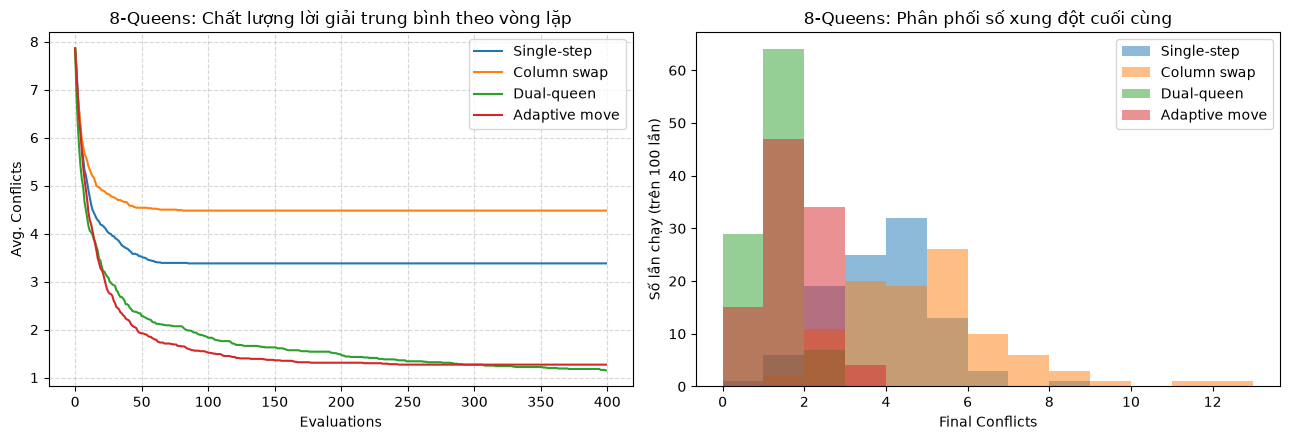

[n=12] Single-step     | Avg final conflicts = 5.20 | Success rate =  0.0% | Avg time (success) = nan ms
[n=12] Column swap     | Avg final conflicts = 6.58 | Success rate =  0.0% | Avg time (success) = nan ms
[n=12] Dual-queen      | Avg final conflicts = 1.52 | Success rate =  5.0% | Avg time (success) = 33.83 ms
[n=12] Adaptive move   | Avg final conflicts = 1.79 | Success rate =  3.0% | Avg time (success) = 8.45 ms


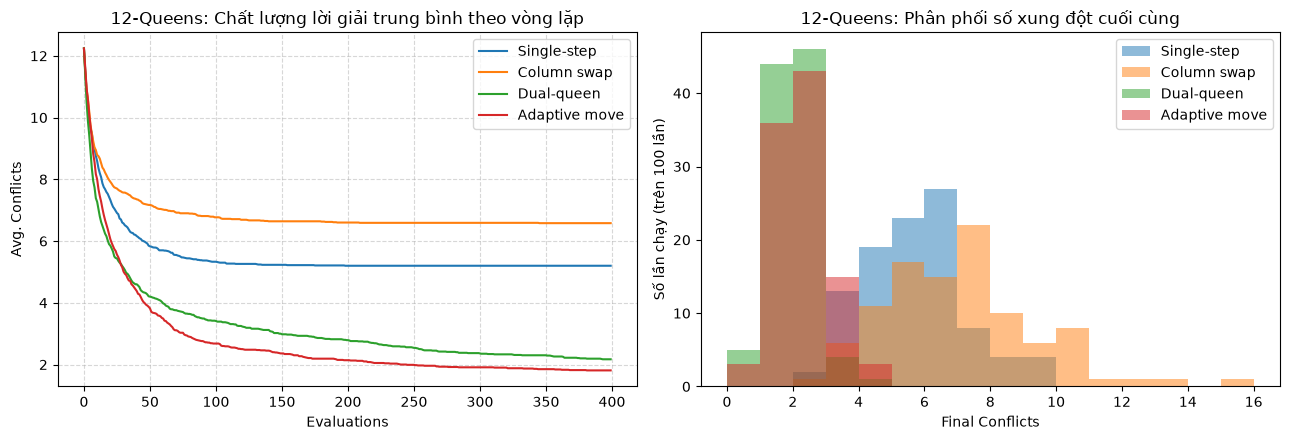

In [15]:
# Cài đặt 4 toán tử di chuyển cục bộ (Local Move Operators) cho n-Queens
def move_single_step(board):
    """Single-step move: Di chuyển 1 quân hậu lên hoặc xuống 1 ô trong cùng cột."""
    n = len(board)
    neighbor = board.copy()
    col = np.random.randint(0, n)
    if neighbor[col] == 0:
        neighbor[col] = 1
    elif neighbor[col] == n - 1:
        neighbor[col] = n - 2
    else:
        neighbor[col] += np.random.choice([-1, 1])
    return neighbor

def move_column_swap(board):
    """Column swap: Hoán đổi vị trí hàng của 2 quân hậu ở 2 cột ngẫu nhiên."""
    n = len(board)
    neighbor = board.copy()
    c1, c2 = np.random.choice(n, size=2, replace=False)
    neighbor[c1], neighbor[c2] = neighbor[c2], neighbor[c1]
    return neighbor

def move_dual_queen(board):
    """Dual-queen move: Chọn 2 cột ngẫu nhiên và đổi hàng đồng thời cho cả 2 quân hậu."""
    n = len(board)
    neighbor = board.copy()
    c1, c2 = np.random.choice(n, size=2, replace=False)
    neighbor[c1] = np.random.randint(0, n)
    neighbor[c2] = np.random.randint(0, n)
    return neighbor

def move_adaptive(board, bad_tries=0):
    """
    Adaptive move:
    - Khi mới tìm kiếm (bad_tries thấp): dùng bước chuyển 1 quân hậu bất kỳ hoặc hoán đổi cột.
    - Khi khó cải thiện (bad_tries cao): tìm quân hậu đang tham gia vào nhiều xung đột nhất để đổi hàng,
      hoặc thực hiện Dual-queen move để thoát khỏi vùng trũng hẹp.
    """
    n = len(board)
    neighbor = board.copy()
    if bad_tries < n:
        col = np.random.randint(0, n)
        neighbor[col] = np.random.randint(0, n)
    else:
        # Tính xung đột của từng cột để ưu tiên di chuyển quân hậu gây xung đột nhiều nhất
        col_conflicts = np.zeros(n, dtype=int)
        for i in range(n):
            for j in range(i + 1, n):
                if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                    col_conflicts[i] += 1
                    col_conflicts[j] += 1
        probs = col_conflicts + 1.0
        probs /= probs.sum()
        col = np.random.choice(n, p=probs)
        neighbor[col] = np.random.randint(0, n)
    return neighbor

def eshc_with_operator(board, operator_fn, max_evals=1500):
    current = np.array(board, copy=True)
    current_obj = conflicts(current)
    history = [current_obj]
    bad_tries = 0

    for _ in range(max_evals):
        if current_obj == 0:
            break
        if operator_fn == move_adaptive:
            neighbor = operator_fn(current, bad_tries)
        else:
            neighbor = operator_fn(current)
        obj = conflicts(neighbor)
        if obj < current_obj:
            current = neighbor
            current_obj = obj
            bad_tries = 0
        else:
            bad_tries += 1
        history.append(current_obj)

    # Pad history cho đủ độ dài để tính trung bình theo vòng lặp
    if len(history) < max_evals + 1:
        history.extend([current_obj] * (max_evals + 1 - len(history)))
    return current, current_obj, history

# Thực nghiệm 100 lần trên 8-Queens và 12-Queens
operators = [
    ("Single-step", move_single_step),
    ("Column swap", move_column_swap),
    ("Dual-queen", move_dual_queen),
    ("Adaptive move", move_adaptive)
]

for n_prob in [8, 12]:
    np.random.seed(1234)
    init_boards = [random_board(n_prob) for _ in range(100)]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    for op_name, op_fn in operators:
        all_hists = []
        final_objs = []
        succ_times = []

        for b in init_boards:
            t0 = time.perf_counter()
            _, f_obj, h = eshc_with_operator(b, op_fn, max_evals=1000)
            dt = (time.perf_counter() - t0) * 1000.0
            all_hists.append(h)
            final_objs.append(f_obj)
            if f_obj == 0:
                succ_times.append(dt)

        mean_hist = np.mean(all_hists, axis=0)
        succ_rate = np.mean(np.array(final_objs) == 0) * 100
        avg_t_succ = np.mean(succ_times) if len(succ_times) > 0 else float('nan')
        print(f"[n={n_prob:2d}] {op_name:15s} | Avg final conflicts = {np.mean(final_objs):.2f} | Success rate = {succ_rate:4.1f}% | Avg time (success) = {avg_t_succ:.2f} ms")

        axes[0].plot(mean_hist[:400], label=op_name)
        axes[1].hist(final_objs, bins=range(0, max(final_objs)+2), alpha=0.5, label=op_name)

    axes[0].set_title(f"{n_prob}-Queens: Chất lượng lời giải trung bình theo vòng lặp")
    axes[0].set_xlabel("Evaluations")
    axes[0].set_ylabel("Avg. Conflicts")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.5)

    axes[1].set_title(f"{n_prob}-Queens: Phân phối số xung đột cuối cùng")
    axes[1].set_xlabel("Final Conflicts")
    axes[1].set_ylabel("Số lần chạy (trên 100 lần)")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [16]:
def genetic_algorithm_nqueens(n, pop_size=100, generations=300, mutation_rate=0.2):
    """Giải bài toán n-Queens bằng Giải thuật Di truyền (Genetic Algorithm)."""
    population = [random_board(n) for _ in range(pop_size)]

    for gen in range(generations):
        objs = np.array([conflicts(ind) for ind in population])
        best_idx = np.argmin(objs)
        if objs[best_idx] == 0:
            return population[best_idx], 0, gen

        # Fitness tỉ lệ nghịch với số xung đột
        fitness = 1.0 / (1.0 + objs)
        probs = fitness / fitness.sum()

        # Elitism: Giữ lại 10% cá thể tốt nhất
        elite_indices = np.argsort(objs)[:pop_size // 10]
        new_pop = [population[i].copy() for i in elite_indices]

        while len(new_pop) < pop_size:
            p1, p2 = np.random.choice(pop_size, size=2, replace=False, p=probs)
            cut = np.random.randint(1, n)
            child = np.concatenate([population[p1][:cut], population[p2][cut:]])
            if np.random.rand() < mutation_rate:
                col = np.random.randint(0, n)
                child[col] = np.random.randint(0, n)
            new_pop.append(child)

        population = new_pop

    objs = np.array([conflicts(ind) for ind in population])
    best_idx = np.argmin(objs)
    return population[best_idx], objs[best_idx], generations

np.random.seed(1234)
ga_board, ga_obj, ga_gen = genetic_algorithm_nqueens(8)
print(f"[Genetic Algorithm 8-Queens] Tìm được nghiệm f = {ga_obj} tại thế hệ {ga_gen}: {ga_board}")

[Genetic Algorithm 8-Queens] Tìm được nghiệm f = 0 tại thế hệ 111: [3 0 4 7 1 6 2 5]
